In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
cancer = load_breast_cancer(as_frame=True)
df = cancer.frame.copy()
X = df.drop(columns=["target"])
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 455
Testing samples: 114


In [3]:
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)

print("Actual Labels:")
print(y_test.values[:10])

print("\nPredicted Labels:")
print(y_pred[:10])

print("\nPrediction Probabilities:")
print(y_prob[:10])

Actual Labels:
[0 1 0 1 0 1 1 0 0 0]

Predicted Labels:
[0 1 0 1 0 1 1 0 0 0]

Prediction Probabilities:
[[9.99999941e-01 5.88824186e-08]
 [1.13351672e-05 9.99988665e-01]
 [9.93589175e-01 6.41082462e-03]
 [4.66491463e-01 5.33508537e-01]
 [9.99999999e-01 6.52500097e-10]
 [7.83960163e-03 9.92160398e-01]
 [1.71746799e-05 9.99982825e-01]
 [9.99999436e-01 5.63527494e-07]
 [9.99945684e-01 5.43163692e-05]
 [1.00000000e+00 8.04184941e-11]]


In [4]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[41  1]
 [ 1 71]]


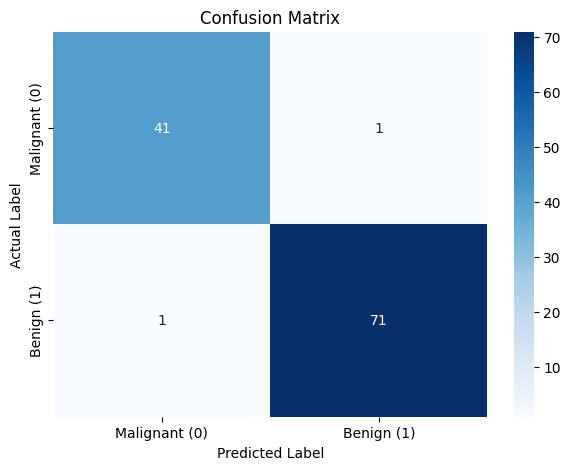

In [5]:
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Malignant (0)", "Benign (1)"],
    yticklabels=["Malignant (0)", "Benign (1)"]
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [7]:
TN, FP, FN, TP = cm.ravel()
accuracy = (TP + TN) / (TP + TN + FP + FN)

precision = TP / (TP + FP)

recall = TP / (TP + FN)

f1_score = 2 * (precision * recall) / (precision + recall)

specificity = TN / (TN + FP)

print("Manual Classification Metrics")
print(f"Accuracy:{accuracy:.4f}")
print(f"Precision:{precision:.4f}")
print(f"Recall:{recall:.4f}")
print(f"F1-Score:{f1_score:.4f}")
print(f"Specificity:{specificity:.4f}")

Manual Classification Metrics
Accuracy:0.9825
Precision:0.9861
Recall:0.9861
F1-Score:0.9861
Specificity:0.9762


In [8]:
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_score,
    recall_score)
sklearn_values = [
    accuracy_score(y_test, y_pred),
    precision_score(y_test, y_pred, pos_label=1),
    recall_score(y_test, y_pred, pos_label=1),
    classification_report(
        y_test, y_pred, output_dict=True
    )["1"]["f1-score"]
]
manual_values = [
    accuracy,
    precision,
    recall,
    f1_score
]
comparison = pd.DataFrame(
    {
        "Manual Calculation": manual_values,
        "Scikit-learn": sklearn_values
    },
    index=["Accuracy", "Precision", "Recall", "F1-Score"]
)
display(comparison.round(4))
print(classification_report(y_test,y_pred,target_names=["Malignant", "Benign"]))

,Manual Calculation,Scikit-learn
Accuracy,0.9825,0.9825
Precision,0.9861,0.9861
Recall,0.9861,0.9861
F1-Score,0.9861,0.9861


              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



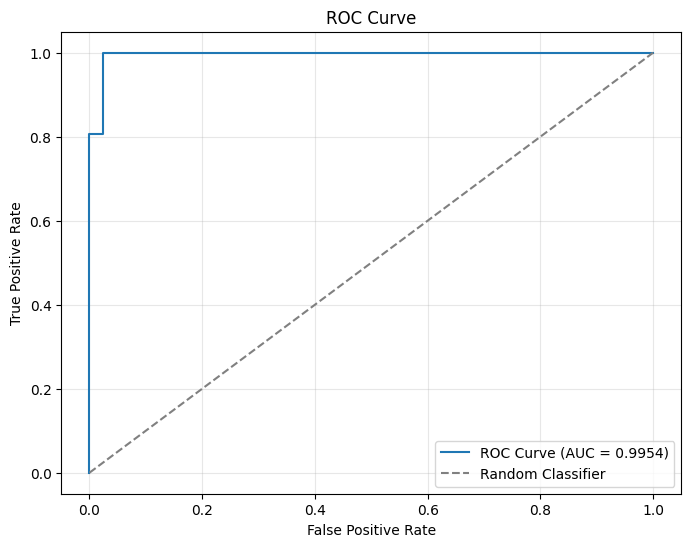

ROC-AUC: 0.9953703703703703


In [9]:
from sklearn.metrics import roc_curve, roc_auc_score
benign_probabilities = y_prob[:, 1]
fpr, tpr, thresholds = roc_curve(
    y_test,
    benign_probabilities,
    pos_label=1
)
auc_value = roc_auc_score(y_test, benign_probabilities)
plt.figure(figsize=(8, 6))
plt.plot(
    fpr,
    tpr,
    label=f"ROC Curve (AUC = {auc_value:.4f})"
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
print("ROC-AUC:", auc_value)

In [10]:
from sklearn.metrics import precision_score, recall_score, f1_score
thresholds_to_test = [0.3, 0.5, 0.7]
results = []
for threshold in thresholds_to_test:

    y_threshold_pred = (
        y_prob[:, 1] >= threshold
    ).astype(int)
    precision = precision_score(
        y_test, y_threshold_pred, pos_label=1
    )
    recall = recall_score(
        y_test, y_threshold_pred, pos_label=1
    )
    f1 = f1_score(
        y_test, y_threshold_pred, pos_label=1
    )
    results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })
threshold_comparison = pd.DataFrame(results)
display(threshold_comparison.round(4))

,Threshold,Precision,Recall,F1-Score
0,0.3,0.9730,1.0000,0.9863
1,0.5,0.9861,0.9861,0.9861
2,0.7,0.9853,0.9306,0.9571


### Threshold Comparison Analysis

When the threshold decreases to 0.3, recall increases to 100%, meaning the model identifies all actual Benign samples, but precision decreases slightly to 97.30%. When the threshold increases to 0.7, precision remains high at 98.53%, while recall decreases to 93.06%, meaning some actual Benign samples are missed. At the default threshold of 0.5, precision and recall are balanced at 98.61%. This demonstrates the trade-off between precision and recall when adjusting the classification threshold.